# v0.3 acceptance checks: do the released files match what Anders asked for?

This notebook plays the role of the second author receiving the three CSVs and checking them against
what he specified and what FCDS requires. Each check prints **PASS**, **FAIL** or **NOTE** and, where a
picture helps, draws one. The checks come from three sources:

1. **His noise specification** (working notebook, 2026-02-02): *"Finder file: 20% missing SSN, 1% transposition
   error SSN, 5% missing Address. FCDS file: 5% missing SSN, 0% (no) transposition error SSN, 1% missing Address."*
2. **His age/sex table** of cases reported by FCDS (`reference/fcds_incidence_by_age_sex.csv`; he excluded the
   1,605 unknown-sex cases on purpose), which the registry stand-in is drawn to match.
3. **FCDS's own rules and the agreed design**: the minimum field sets a finder file must carry (Procedure Guide and
   current Data Linkage Record Layout), the file sizes and overlaps, and the ground-truth key.

Everything here reads only the released CSVs, the small summaries in `results/`, and the reference table, so
anyone holding the deposit can rerun it. Run from the repository root with `uv run jupyter nbconvert --execute`,
or open it in VS Code with the project kernel.

In [1]:
import json, re, hashlib
from pathlib import Path
import duckdb, pandas as pd, numpy as np, yaml
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
CFG = yaml.safe_load((ROOT / "config.yaml").read_text())
RELEASE = Path(CFG["paths"]["release_dir"])
RESULTS = ROOT / CFG["paths"]["results"]
MANIFEST = json.load(open(RESULTS / "release_manifest.json"))
FILES = ["registry.csv", "finder_500k.csv", "finder_100k.csv"]
FINDERS = FILES[1:]

BLUE, ORANGE, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False})

LOG = []
def check(name, ok, detail=""):
    LOG.append((name, "PASS" if ok else "FAIL", detail))
    print(("PASS " if ok else "FAIL ") + name + (" -- " + detail if detail else ""))
def note(name, detail=""):
    LOG.append((name, "NOTE", detail))
    print("NOTE " + name + (" -- " + detail if detail else ""))

print("release:", RELEASE)
print("dataset version:", MANIFEST["version"], "| registry pool:", MANIFEST["registry_pool"], MANIFEST["census_years"], "| finder year:", MANIFEST["finder_year"])

release: /ihme/homes/abie/notebook/2026/data/sim_cancer_registry_linkage_benchmark_0.3
dataset version: 0.3 | registry pool: last_seen [2020, 2030, 2040] | finder year: 2040


## 0. Load the three files
DuckDB reads the CSVs as text. The files quote the rare comma-containing value, so the quote character is named explicitly.

In [2]:
con = duckdb.connect()
READ = "header=true, all_varchar=true, quote='\"'"
for f in FILES:
    con.execute(f"CREATE OR REPLACE TABLE {f[:-4]} AS SELECT * FROM read_csv('{RELEASE / f}', {READ})")
counts = con.execute("""
    SELECT 'registry.csv' AS file, count(*) AS rows, count(DISTINCT simulant_id) AS people FROM registry
    UNION ALL SELECT 'finder_500k.csv', count(*), count(DISTINCT simulant_id) FROM finder_500k
    UNION ALL SELECT 'finder_100k.csv', count(*), count(DISTINCT simulant_id) FROM finder_100k
""").df().set_index("file")
counts

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,rows,people
file,,
registry.csv,5000002,5000000
finder_500k.csv,500000,500000
finder_100k.csv,100001,100000


## 1. Are these the files that were profiled? Checksums against the release manifest

In [3]:
def digests(path, chunk=1 << 24):
    md5, sha = hashlib.md5(), hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            md5.update(block); sha.update(block)
    return md5.hexdigest(), sha.hexdigest()

for f in FILES:
    md5, sha = digests(RELEASE / f)
    m = MANIFEST["files"][f]
    check(f"{f}: MD5 and SHA-256 match the manifest", md5 == m["md5"] and sha == m["sha256"], f"MD5 {md5[:8]}..., {m['size_bytes']/1e6:.1f} MB")
zip_path = RELEASE.parent / MANIFEST["zip"]["name"]
if zip_path.exists():
    md5, sha = digests(zip_path)
    check("zip bundle: MD5 and SHA-256 match the manifest", md5 == MANIFEST["zip"]["md5"] and sha == MANIFEST["zip"]["sha256"], f"{MANIFEST['zip']['size_bytes']/1e6:.0f} MB")
else:
    note("zip bundle not found beside the release directory", str(zip_path))

PASS registry.csv: MD5 and SHA-256 match the manifest -- MD5 0656cd4b..., 509.8 MB
PASS finder_500k.csv: MD5 and SHA-256 match the manifest -- MD5 6025e406..., 49.9 MB


PASS finder_100k.csv: MD5 and SHA-256 match the manifest -- MD5 ffbc3a53..., 10.0 MB


PASS zip bundle: MD5 and SHA-256 match the manifest -- 219 MB


## 2. Layout and size: the agreed columns, 5,000,000 / 500,000 / 100,000 people
Rows can exceed people when pseudopeople's duplication noise emits two rows for one simulant; that is deliberate and small.

In [4]:
c = CFG["cohorts"]
for f in FILES:
    cols = [r[0] for r in con.execute(f"DESCRIBE {f[:-4]}").fetchall()]
    check(f"{f}: columns are exactly the published layout", cols == MANIFEST["columns"], ", ".join(cols))
targets = {"registry.csv": c["registry_target"], "finder_500k.csv": c["finder_500k_target"], "finder_100k.csv": c["finder_100k_target"]}
for f, t in targets.items():
    people, rows = int(counts.loc[f, "people"]), int(counts.loc[f, "rows"])
    check(f"{f}: {people:,} distinct people (target {t:,})", people == t, f"{rows - people} duplicated row(s) from duplication noise")

PASS registry.csv: columns are exactly the published layout -- simulant_id, first_name, middle_initial, last_name, date_of_birth, sex, race_ethnicity, street_number, street_name, unit_number, city, state, zipcode, ssn
PASS finder_500k.csv: columns are exactly the published layout -- simulant_id, first_name, middle_initial, last_name, date_of_birth, sex, race_ethnicity, street_number, street_name, unit_number, city, state, zipcode, ssn
PASS finder_100k.csv: columns are exactly the published layout -- simulant_id, first_name, middle_initial, last_name, date_of_birth, sex, race_ethnicity, street_number, street_name, unit_number, city, state, zipcode, ssn
PASS registry.csv: 5,000,000 distinct people (target 5,000,000) -- 2 duplicated row(s) from duplication noise
PASS finder_500k.csv: 500,000 distinct people (target 500,000) -- 0 duplicated row(s) from duplication noise
PASS finder_100k.csv: 100,000 distinct people (target 100,000) -- 1 duplicated row(s) from duplication noise


## 3. Overlaps and ground truth: 100,000 and 20,000 people shared with the registry, none between the finder files

PASS finder_500k shares exactly 100,000 people with the registry -- 100,000 (match prevalence 0.200)
PASS finder_100k shares exactly 20,000 people with the registry -- 20,000 (match prevalence 0.200)
PASS the two finder files share no people -- 0 shared
PASS every row carries a simulant_id (the ground-truth key) -- 0 blank ids


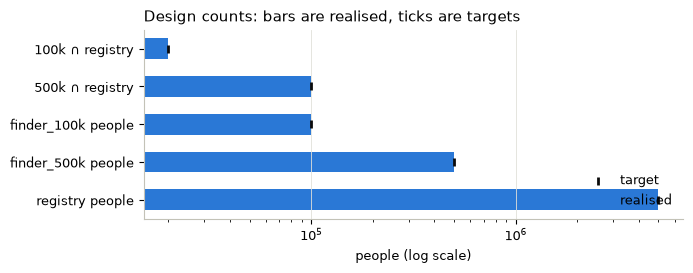

In [5]:
ov = con.execute("""
    SELECT
      (SELECT count(DISTINCT simulant_id) FROM finder_500k WHERE simulant_id IN (SELECT simulant_id FROM registry)) AS ov_500k,
      (SELECT count(DISTINCT simulant_id) FROM finder_100k WHERE simulant_id IN (SELECT simulant_id FROM registry)) AS ov_100k,
      (SELECT count(DISTINCT simulant_id) FROM finder_500k WHERE simulant_id IN (SELECT simulant_id FROM finder_100k)) AS ov_ff,
      (SELECT count(*) FROM registry WHERE simulant_id IS NULL OR simulant_id = '') +
      (SELECT count(*) FROM finder_500k WHERE simulant_id IS NULL OR simulant_id = '') +
      (SELECT count(*) FROM finder_100k WHERE simulant_id IS NULL OR simulant_id = '') AS null_ids
""").df().iloc[0]
check("finder_500k shares exactly 100,000 people with the registry", ov.ov_500k == c["overlap_500k_target"], f"{int(ov.ov_500k):,} (match prevalence {ov.ov_500k / c['finder_500k_target']:.3f})")
check("finder_100k shares exactly 20,000 people with the registry", ov.ov_100k == c["overlap_100k_target"], f"{int(ov.ov_100k):,} (match prevalence {ov.ov_100k / c['finder_100k_target']:.3f})")
check("the two finder files share no people", ov.ov_ff == 0, f"{int(ov.ov_ff)} shared")
check("every row carries a simulant_id (the ground-truth key)", ov.null_ids == 0, f"{int(ov.null_ids)} blank ids")

design = pd.DataFrame({
    "target":   [c["registry_target"], c["finder_500k_target"], c["finder_100k_target"], c["overlap_500k_target"], c["overlap_100k_target"]],
    "realised": [counts.loc["registry.csv","people"], counts.loc["finder_500k.csv","people"], counts.loc["finder_100k.csv","people"], ov.ov_500k, ov.ov_100k]},
    index=["registry people", "finder_500k people", "finder_100k people", "500k ∩ registry", "100k ∩ registry"])
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(design.index, design["realised"], color=BLUE, height=0.55, label="realised")
ax.scatter(design["target"], design.index, color=INK, zorder=3, s=30, marker="|", linewidths=2, label="target")
ax.set_xscale("log"); ax.set_xlabel("people (log scale)"); ax.grid(axis="x", color=GRID, lw=0.6); ax.legend(frameon=False, loc="lower right")
ax.set_title("Design counts: bars are realised, ticks are targets", loc="left"); plt.tight_layout()

## 4. Anders's noise specification

*Finder file: 20% missing SSN, 1% transposition error SSN, 5% missing Address. FCDS file: 5% missing SSN, 0% transposition, 1% missing Address.*

Two things to know when reading the chart. The **registry's SSN target is a floor**: 5.7% of people in the registry pool never held an SSN in the source population, so nothing further is blanked and the realised rate sits above 5%. And two address fields carry **structural blanks from the source** on top of the 5%/1% noise: `unit_number` is blank for most addresses (no unit) and `street_number` for some, so the test uses `street_name`, `city`, `state` and `zipcode`.

,registry,finder_500k,finder_100k
ssn,5.685%,20.000%,20.000%
street_number,5.604%,9.531%,9.440%
street_name,1.003%,4.985%,4.959%
unit_number,94.232%,94.294%,94.434%
city,0.998%,5.007%,4.976%
state,0.999%,5.003%,4.989%
zipcode,1.001%,4.994%,4.977%


PASS finder_500k: SSN missing 20% -- 20.00%
PASS finder_500k: 5% missing on each clean address field -- street_name 4.98%, city 5.01%, state 5.00%, zipcode 4.99%
PASS finder_100k: SSN missing 20% -- 20.00%
PASS finder_100k: 5% missing on each clean address field -- street_name 4.96%, city 4.98%, state 4.99%, zipcode 4.98%
PASS registry: SSN missing at least 5% (target is a floor; structural 5.7%) -- 5.68%
PASS registry: 1% missing on each clean address field -- street_name 1.00%, city 1.00%, state 1.00%, zipcode 1.00%
NOTE street_number carries source blanks on top of the noise -- registry 5.6%, finder_500k 9.5%, finder_100k 9.4%
NOTE unit_number is blank for most addresses by construction -- registry 94.2%, finder_500k 94.3%, finder_100k 94.4%


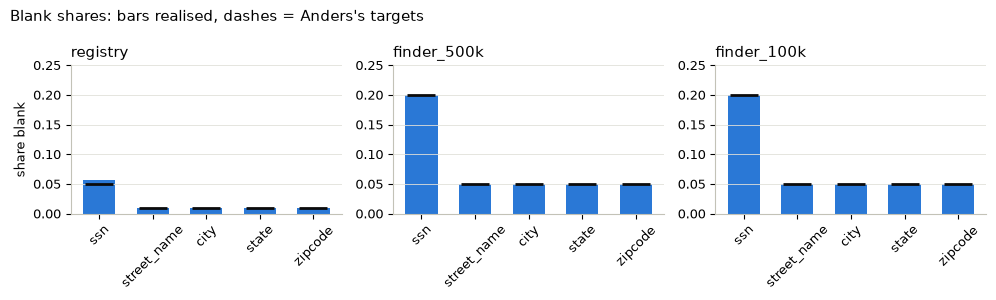

In [6]:
ADDR = ["street_number", "street_name", "unit_number", "city", "state", "zipcode"]
def missing_shares(table):
    sel = ", ".join(f"avg((({col} IS NULL) OR ({col} = ''))::INT) AS {col}" for col in ["ssn"] + ADDR)
    return con.execute(f"SELECT {sel} FROM {table}").df().iloc[0]
miss = pd.DataFrame({f[:-4]: missing_shares(f[:-4]) for f in FILES})
noise = CFG["noise"]
tgt = pd.DataFrame({"registry": [noise["registry"]["ssn_missing"]] + [noise["registry"]["address_missing"]] * 6,
                    "finder_500k": [noise["finder"]["ssn_missing"]] + [noise["finder"]["address_missing"]] * 6,
                    "finder_100k": [noise["finder"]["ssn_missing"]] + [noise["finder"]["address_missing"]] * 6}, index=miss.index)
display(miss.style.format("{:.3%}").set_caption("realised share blank"))

clean_addr = ["street_name", "city", "state", "zipcode"]
for t in ("finder_500k", "finder_100k"):
    check(f"{t}: SSN missing 20%", abs(miss.loc["ssn", t] - 0.20) < 0.005, f"{miss.loc['ssn', t]:.2%}")
    worst = (miss.loc[clean_addr, t] - 0.05).abs().max()
    check(f"{t}: 5% missing on each clean address field", worst < 0.005, ", ".join(f"{a} {miss.loc[a, t]:.2%}" for a in clean_addr))
check("registry: SSN missing at least 5% (target is a floor; structural 5.7%)", miss.loc["ssn", "registry"] >= 0.05, f"{miss.loc['ssn', 'registry']:.2%}")
worst = (miss.loc[clean_addr, "registry"] - 0.01).abs().max()
check("registry: 1% missing on each clean address field", worst < 0.003, ", ".join(f"{a} {miss.loc[a, 'registry']:.2%}" for a in clean_addr))
note("street_number carries source blanks on top of the noise", ", ".join(f"{t} {miss.loc['street_number', t]:.1%}" for t in miss.columns))
note("unit_number is blank for most addresses by construction", ", ".join(f"{t} {miss.loc['unit_number', t]:.1%}" for t in miss.columns))

fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=False)
for ax, t in zip(axes, miss.columns):
    rows = ["ssn"] + clean_addr
    ax.bar(rows, miss.loc[rows, t], color=BLUE, width=0.6)
    ax.scatter(rows, tgt.loc[rows, t], color=INK, marker="_", s=400, linewidths=2, zorder=3)
    ax.set_title(t, loc="left"); ax.set_ylim(0, 0.25); ax.tick_params(axis="x", rotation=45); ax.grid(axis="y", color=GRID, lw=0.6)
axes[0].set_ylabel("share blank"); fig.suptitle("Blank shares: bars realised, dashes = Anders's targets", x=0.01, ha="left"); plt.tight_layout()

### 4b. SSN transposition: 1% in the finder files, none in the registry
The released files do not carry the clean SSN, but the true pairs do the job: the registry has no SSN noise, so when a finder SSN differs from its registry twin, the difference is the finder's error. An adjacent-digit swap is the only error requested.

In [7]:
import sys; sys.path.insert(0, str(ROOT / "src"))
from simulated_data_for_fcds_scale_rl.record_diff import is_adjacent_transposition

for t in ("finder_500k", "finder_100k"):
    pairs = con.execute(f"""
        SELECT r.ssn AS r_ssn, f.ssn AS f_ssn
        FROM (SELECT * FROM registry QUALIFY row_number() OVER (PARTITION BY simulant_id) = 1) r
        JOIN (SELECT * FROM {t} QUALIFY row_number() OVER (PARTITION BY simulant_id) = 1) f USING (simulant_id)
        WHERE r.ssn IS NOT NULL AND r.ssn <> '' AND f.ssn IS NOT NULL AND f.ssn <> ''
    """).df()
    differ = pairs[pairs.r_ssn != pairs.f_ssn]
    swaps = differ.apply(lambda x: is_adjacent_transposition(x.r_ssn.replace("-", ""), x.f_ssn.replace("-", "")), axis=1).sum() if len(differ) else 0
    rate = swaps / len(pairs)
    # A swap of two equal adjacent digits (about one draw in ten) changes nothing and cannot be seen, so the visible
    # rate runs a little under the 1% applied.
    check(f"{t}: adjacent-digit SSN swaps at about 1% of present SSNs (visible swaps; equal-digit swaps are invisible)", 0.008 <= rate <= 0.0105, f"{swaps:,} visible swaps in {len(pairs):,} pairs with both SSNs = {rate:.2%}")
    check(f"{t}: every SSN disagreement is an adjacent swap (so the registry SSN is clean)", swaps == len(differ), f"{len(differ) - swaps} other disagreements")

PASS finder_500k: adjacent-digit SSN swaps at about 1% of present SSNs (visible swaps; equal-digit swaps are invisible) -- 671 visible swaps in 78,594 pairs with both SSNs = 0.85%
PASS finder_500k: every SSN disagreement is an adjacent swap (so the registry SSN is clean) -- 0 other disagreements


PASS finder_100k: adjacent-digit SSN swaps at about 1% of present SSNs (visible swaps; equal-digit swaps are invisible) -- 154 visible swaps in 15,572 pairs with both SSNs = 0.99%
PASS finder_100k: every SSN disagreement is an adjacent swap (so the registry SSN is clean) -- 0 other disagreements


## 5. Age and sex: does the registry follow Anders's table of FCDS cases?

Two views. **The check that matters** uses each person's true age at the year of their record (the build writes it to `results/registry_age_sex.csv`, because the released files carry no age or record year). **The view a user would try first**, deriving age from the date of birth at a fixed reference date, does *not* line up, and the reason is worth seeing: 27% of registry records are people last seen in 2020 and 27% in 2030, so ages computed as of 2040 are 10 to 20 years too high for them, and ages computed as of 2020 are too low for the rest.

PASS registry age/sex shares match Anders's FCDS table (true age at record year) -- largest deviation 0.041 percentage points (Male 45+)


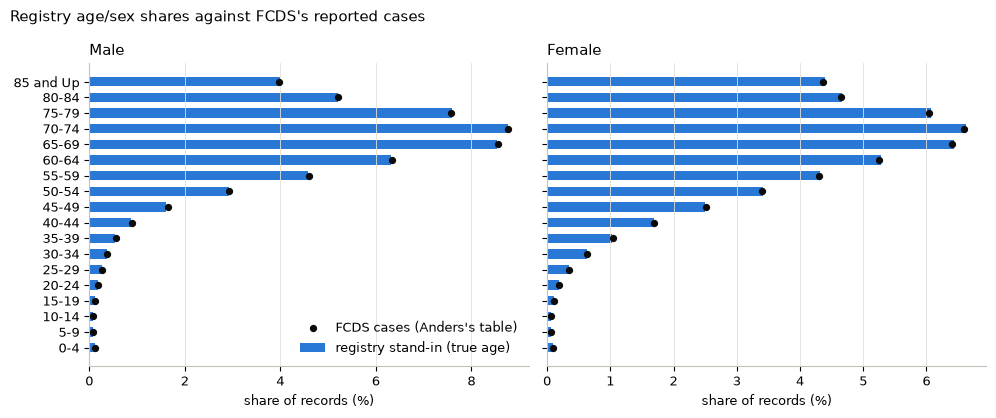

In [8]:
fcds = pd.read_csv(ROOT / CFG["paths"]["age_sex_target"], comment="#"); fcds["sex"] = fcds.sex.str.capitalize()
fcds["share"] = fcds["count"] / fcds["count"].sum()
bins = fcds[fcds.sex == "Male"][["age_start", "age_end", "age_group"]].sort_values("age_start").reset_index(drop=True)
target = fcds.set_index(["sex", "age_start"])["share"]

true_ages = pd.read_csv(RESULTS / "registry_age_sex.csv")
reg = true_ages[true_ages.file == "registry.csv"].groupby(["sex", "age_start"])["count"].sum()
reg_share = (reg / reg.sum()).reindex(target.index).fillna(0)
dev_pp = (reg_share - target) * 100
check("registry age/sex shares match Anders's FCDS table (true age at record year)", dev_pp.abs().max() < 0.1, f"largest deviation {dev_pp.abs().max():.3f} percentage points ({dev_pp.abs().idxmax()[0]} {int(dev_pp.abs().idxmax()[1])}+)")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, sex in zip(axes, ["Male", "Female"]):
    y = np.arange(len(bins))
    ax.barh(y, reg_share.loc[sex].reindex(bins.age_start).to_numpy() * 100, color=BLUE, height=0.6, label="registry stand-in (true age)")
    ax.scatter(target.loc[sex].reindex(bins.age_start).to_numpy() * 100, y, color=INK, zorder=3, s=18, label="FCDS cases (Anders's table)")
    ax.set_yticks(y); ax.set_yticklabels(bins.age_group); ax.set_title(sex, loc="left"); ax.grid(axis="x", color=GRID, lw=0.6); ax.set_xlabel("share of records (%)")
axes[0].legend(frameon=False, loc="lower right"); fig.suptitle("Registry age/sex shares against FCDS's reported cases", x=0.01, ha="left"); plt.tight_layout()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

NOTE registry records by census year (record vintage) -- 2020: 1,329,059 (27%), 2030: 1,376,079 (28%), 2040: 2,294,864 (46%)
NOTE ages derived from DOB at one reference date do not reproduce the FCDS pattern -- the released registry has no record-year column; a user needs one to compute age at record. Decision for the authors.


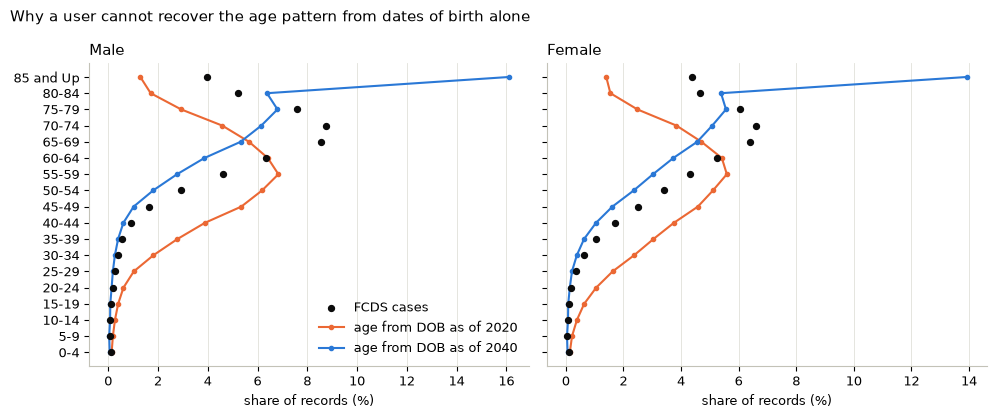

In [9]:
# The naive view: age from the date of birth at a fixed reference date, for the registry file itself.
con.register("bins_df", bins)
def dob_shares(table, ref):
    df = con.execute(f"""
        WITH aged AS (
            SELECT sex, try_strptime(date_of_birth, '%m/%d/%Y') AS dob,
                   year(DATE '{ref}') - year(try_strptime(date_of_birth, '%m/%d/%Y'))
                   - CASE WHEN (month(try_strptime(date_of_birth, '%m/%d/%Y')), day(try_strptime(date_of_birth, '%m/%d/%Y'))) > (month(DATE '{ref}'), day(DATE '{ref}')) THEN 1 ELSE 0 END AS age
            FROM {table})
        SELECT a.sex, b.age_start, count(*) AS n FROM aged a JOIN bins_df b ON a.age >= b.age_start AND a.age < b.age_end
        WHERE a.sex IN ('Male', 'Female') GROUP BY ALL
    """).df().set_index(["sex", "age_start"])["n"]
    return (df / df.sum()).reindex(target.index).fillna(0)
by_ref = {ref: dob_shares("registry", f"{ref}-04-01") for ref in (2020, 2040)}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, sex in zip(axes, ["Male", "Female"]):
    y = np.arange(len(bins))
    ax.scatter(target.loc[sex].reindex(bins.age_start) * 100, y, color=INK, s=18, zorder=3, label="FCDS cases")
    ax.plot(by_ref[2020].loc[sex].reindex(bins.age_start) * 100, y, color=ORANGE, marker="o", ms=3, label="age from DOB as of 2020")
    ax.plot(by_ref[2040].loc[sex].reindex(bins.age_start) * 100, y, color=BLUE, marker="o", ms=3, label="age from DOB as of 2040")
    ax.set_yticks(y); ax.set_yticklabels(bins.age_group); ax.set_title(sex, loc="left"); ax.grid(axis="x", color=GRID, lw=0.6); ax.set_xlabel("share of records (%)")
axes[0].legend(frameon=False, loc="lower right"); fig.suptitle("Why a user cannot recover the age pattern from dates of birth alone", x=0.01, ha="left"); plt.tight_layout()
qa = json.load(open(RESULTS / "age_sex_qa.json"))["registry.csv"]["rows_by_census_year"]
note("registry records by census year (record vintage)", ", ".join(f"{y}: {n:,} ({n / sum(qa.values()):.0%})" for y, n in qa.items()))
note("ages derived from DOB at one reference date do not reproduce the FCDS pattern", "the released registry has no record-year column; a user needs one to compute age at record. Decision for the authors.")

## 6. Sex coding
Anders excluded 1,605 unknown-sex cases from his table. The simulated files carry a little blank or wrong sex from pseudopeople's default noise (1% blank, 1% wrong option), which is what a real finder file does too.

In [10]:
sex = pd.DataFrame({f[:-4]: con.execute(f"SELECT coalesce(nullif(sex, ''), '(blank)') AS sex, count(*) n FROM {f[:-4]} GROUP BY 1").df().set_index("sex")["n"] for f in FILES}).fillna(0).astype(int)
display((sex / sex.sum()).style.format("{:.2%}").set_caption("share of rows by recorded sex"))
fcds_mf = fcds.groupby("sex")["count"].sum(); fcds_mf = fcds_mf / fcds_mf.sum()
reg_mf = reg.groupby(level="sex").sum() / reg.sum()
check("registry male/female split matches FCDS's cases", abs(reg_mf["Male"] - fcds_mf["Male"]) < 0.002, f"registry male {reg_mf['Male']:.3f} vs FCDS {fcds_mf['Male']:.3f}")
note("sex blank or off-category (noise, not error)", ", ".join(f"{t} {(sex.loc[[i for i in sex.index if i not in ('Male', 'Female')], t].sum() / sex[t].sum()):.2%}" for t in sex.columns))

,registry,finder_500k,finder_100k
sex,,,
(blank),1.00%,0.99%,0.99%
Female,47.44%,50.93%,50.87%
Male,51.56%,48.08%,48.14%


PASS registry male/female split matches FCDS's cases -- registry male 0.521 vs FCDS 0.523
NOTE sex blank or off-category (noise, not error) -- registry 1.00%, finder_500k 0.99%, finder_100k 0.99%


## 7. FCDS's minimum field sets: can each finder record be submitted?

The 2007/2016 Procedure Guide requires first and last name **and** SSN **and** sex, *or* first and last name **and** month and year of birth **and** sex. The current Data Linkage Record Layout requires name, sex, DOB and SSN, *or* name, sex, DOB, ZIP and street address. With 20% of SSNs blank by design, the SSN sets cannot be complete for every record; what matters is that nearly every record satisfies at least one set.

,finder_500k,finder_100k
guide: name + SSN + sex,77.6%,77.7%
guide: name + birth month/year + sex,96.1%,96.1%
layout: name + sex + DOB + SSN,76.9%,76.9%
layout: name + sex + DOB + ZIP + street,78.5%,78.6%
guide: either set,96.9%,96.8%
layout: either set,92.5%,92.5%


NOTE finder_500k: records satisfying at least one Procedure Guide minimum set -- 96.9%
NOTE finder_500k: records satisfying at least one current-layout minimum set -- 92.5%
NOTE finder_100k: records satisfying at least one Procedure Guide minimum set -- 96.8%
NOTE finder_100k: records satisfying at least one current-layout minimum set -- 92.5%
PASS finder completeness is consistent with the specified blank rates (guide sets: ~97%) -- finder_500k 96.9%, finder_100k 96.8%


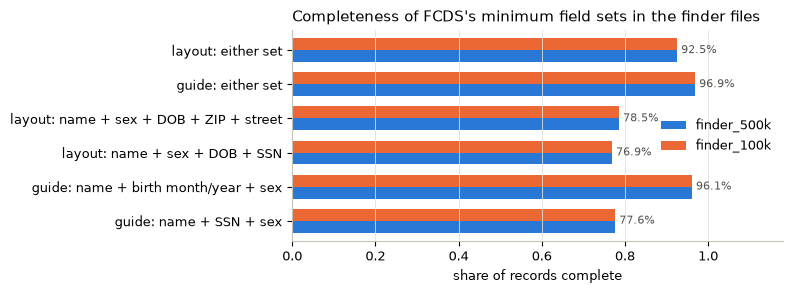

In [11]:
P = lambda col: f"({col} IS NOT NULL AND {col} <> '')"
sets = {
    "guide: name + SSN + sex":              f"{P('first_name')} AND {P('last_name')} AND {P('ssn')} AND {P('sex')}",
    "guide: name + birth month/year + sex": f"{P('first_name')} AND {P('last_name')} AND {P('date_of_birth')} AND {P('sex')}",
    "layout: name + sex + DOB + SSN":        f"{P('first_name')} AND {P('last_name')} AND {P('sex')} AND {P('date_of_birth')} AND {P('ssn')}",
    "layout: name + sex + DOB + ZIP + street": f"{P('first_name')} AND {P('last_name')} AND {P('sex')} AND {P('date_of_birth')} AND {P('zipcode')} AND {P('street_number')} AND {P('street_name')}",
}
rows = {}
for t in ("finder_500k", "finder_100k"):
    sel = ", ".join(f"avg(({q})::INT) AS \"{k}\"" for k, q in sets.items())
    either_guide = f"avg((({sets['guide: name + SSN + sex']}) OR ({sets['guide: name + birth month/year + sex']}))::INT)"
    either_layout = f"avg((({sets['layout: name + sex + DOB + SSN']}) OR ({sets['layout: name + sex + DOB + ZIP + street']}))::INT)"
    r = con.execute(f"SELECT {sel}, {either_guide} AS \"guide: either set\", {either_layout} AS \"layout: either set\" FROM {t}").df().iloc[0]
    rows[t] = r
complete = pd.DataFrame(rows)
display(complete.style.format("{:.1%}").set_caption("share of finder records complete on each field set"))
for t in complete.columns:
    note(f"{t}: records satisfying at least one Procedure Guide minimum set", f"{complete.loc['guide: either set', t]:.1%}")
    note(f"{t}: records satisfying at least one current-layout minimum set", f"{complete.loc['layout: either set', t]:.1%}")
# The shortfall is arithmetic, not a defect: a record needs either an SSN (blank in 20% by specification) or, for the
# layout's alternative, ZIP + street number + street name (each ~5% blank, street number ~9.5% with source blanks), on
# top of ~1% blank first name, last name, sex and DOB. Anders's own rates imply roughly 3% (guide) and 7-8% (layout)
# of finder records that FCDS could not accept as submitted, which is a realistic property of a dirty finder file.
check("finder completeness is consistent with the specified blank rates (guide sets: ~97%)", all(abs(complete.loc["guide: either set", t] - 0.969) < 0.01 for t in complete.columns), ", ".join(f"{t} {complete.loc['guide: either set', t]:.1%}" for t in complete.columns))
fig, ax = plt.subplots(figsize=(8, 3))
complete.plot.barh(ax=ax, color=[BLUE, ORANGE], width=0.7); ax.set_xlim(0, 1.18); ax.set_xlabel("share of records complete"); ax.grid(axis="x", color=GRID, lw=0.6); ax.legend(frameon=False, loc="center right")
for i, (a, b) in enumerate(zip(complete["finder_500k"], complete["finder_100k"])):
    ax.text(max(a, b) + 0.01, i, f"{a:.1%}", va="center", fontsize=8, color=INK2)
ax.set_title("Completeness of FCDS's minimum field sets in the finder files", loc="left"); plt.tight_layout()

## 8. Field formats
SSNs are `ddd-dd-dddd`, dates `MM/DD/YYYY`, ZIP codes five digits, state `FL`. Typo and OCR noise deliberately break a small share of dates and ZIPs; the SSN format is preserved because the only SSN error is a digit swap.

In [12]:
fmt = {}
for f in FILES:
    t = f[:-4]
    fmt[t] = con.execute(f"""
        SELECT avg(regexp_matches(ssn, '^[0-9]{{3}}-[0-9]{{2}}-[0-9]{{4}}$')::INT) FILTER (WHERE {P('ssn')}) AS ssn_format,
               avg((try_strptime(date_of_birth, '%m/%d/%Y') IS NOT NULL)::INT) FILTER (WHERE {P('date_of_birth')}) AS dob_parses,
               avg(regexp_matches(zipcode, '^[0-9]{{5}}$')::INT) FILTER (WHERE {P('zipcode')}) AS zip_5_digits,
               avg((state = 'FL')::INT) FILTER (WHERE {P('state')}) AS state_is_FL,
               avg(regexp_matches(first_name, '^[A-Z][a-z]')::INT) FILTER (WHERE {P('first_name')}) AS first_name_capitalised
        FROM {t}""").df().iloc[0]
fmt = pd.DataFrame(fmt)
display(fmt.style.format("{:.2%}").set_caption("share of non-blank values in the expected format"))
for t in fmt.columns:
    check(f"{t}: every present SSN is ddd-dd-dddd", fmt.loc["ssn_format", t] > 0.9999, f"{fmt.loc['ssn_format', t]:.3%}")
    check(f"{t}: at least 95% of dates of birth parse as MM/DD/YYYY", fmt.loc["dob_parses", t] >= 0.95, f"{fmt.loc['dob_parses', t]:.2%} (the rest is typo/OCR noise)")
note("state and ZIP", ", ".join(f"{t}: FL {fmt.loc['state_is_FL', t]:.2%}, 5-digit ZIP {fmt.loc['zip_5_digits', t]:.2%}" for t in fmt.columns))
note("casing", "names are proper case, street names and cities lower case; the FCDS fixed-width layout wants upper case, which is a conversion step, not a data defect")
bad = con.execute("SELECT date_of_birth FROM finder_500k WHERE date_of_birth <> '' AND try_strptime(date_of_birth, '%m/%d/%Y') IS NULL LIMIT 8").df()
print("examples of dates that fail to parse (deliberate noise):", bad.date_of_birth.tolist())

,registry,finder_500k,finder_100k
ssn_format,100.00%,100.00%,100.00%
dob_parses,98.59%,98.58%,98.57%
zip_5_digits,99.76%,99.77%,99.73%
state_is_FL,99.00%,99.00%,99.02%
first_name_capitalised,99.74%,99.74%,99.74%


PASS registry: every present SSN is ddd-dd-dddd -- 100.000%
PASS registry: at least 95% of dates of birth parse as MM/DD/YYYY -- 98.59% (the rest is typo/OCR noise)
PASS finder_500k: every present SSN is ddd-dd-dddd -- 100.000%
PASS finder_500k: at least 95% of dates of birth parse as MM/DD/YYYY -- 98.58% (the rest is typo/OCR noise)
PASS finder_100k: every present SSN is ddd-dd-dddd -- 100.000%
PASS finder_100k: at least 95% of dates of birth parse as MM/DD/YYYY -- 98.57% (the rest is typo/OCR noise)
NOTE state and ZIP -- registry: FL 99.00%, 5-digit ZIP 99.76%, finder_500k: FL 99.00%, 5-digit ZIP 99.77%, finder_100k: FL 99.02%, 5-digit ZIP 99.73%
NOTE casing -- names are proper case, street names and cities lower case; the FCDS fixed-width layout wants upper case, which is a conversion step, not a data defect
examples of dates that fail to parse (deliberate noise): ['O9/24/2021', '0G/Z9/2022', '01/23/2O28', '21/09/1968', '23/02/2030', '28/05/2030', '72/03/2031', '20/06/2032']


## 9. Does it look like Florida? Names and race/ethnicity at a glance

NOTE race/ethnicity is inherited from the population through age, not designed -- no race-specific cancer rates are modelled


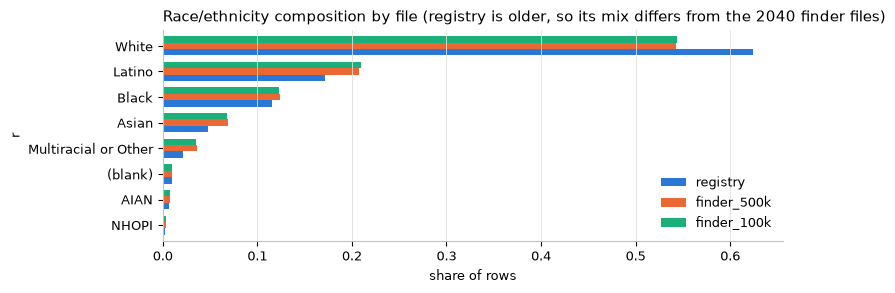

In [13]:
top = pd.read_csv(RESULTS / "registry_top_names.csv")
t = top[(top.file == "registry.csv")].pivot_table(index="age_group", columns=["sex", "rank"], values="first_name", aggfunc="first")
t = t.reindex(bins.age_group)
display(t.style.set_caption("three most common first names in the registry, by age group and sex (as released, noise included)"))
race = pd.DataFrame({f[:-4]: con.execute(f"SELECT coalesce(nullif(race_ethnicity, ''), '(blank)') r, count(*) n FROM {f[:-4]} GROUP BY 1").df().set_index("r")["n"] for f in FILES}).fillna(0)
race = race / race.sum()
fig, ax = plt.subplots(figsize=(8, 3))
race.sort_values("registry", ascending=True).plot.barh(ax=ax, color=[BLUE, ORANGE, "#1baf7a"], width=0.75); ax.set_xlabel("share of rows"); ax.grid(axis="x", color=GRID, lw=0.6); ax.legend(frameon=False)
ax.set_title("Race/ethnicity composition by file (registry is older, so its mix differs from the 2040 finder files)", loc="left"); plt.tight_layout()
note("race/ethnicity is inherited from the population through age, not designed", "no race-specific cancer rates are modelled")

## 10. What a true pair looks like
The ground truth is exact: the same `simulant_id` in two files is the same simulated person. The pipeline picks two worked examples deterministically (`results/example_pair.csv`).

In [14]:
ex = pd.read_csv(RESULTS / "example_pair.csv", dtype=str, keep_default_na=False)
for k, g in ex.groupby("pair"):
    print(f"pair {k}: simulant_id {g.simulant_id.iloc[0]} -- {g.discrepancies.iloc[0]}")
    display(g.drop(columns=["pair", "simulant_id", "discrepancies"]).set_index("source").T)

pair 1: simulant_id 3621_251157 -- first_name: nickname or different name; city: typo; state: blank; ssn: adjacent digits swapped


source,registry,finder_500k
first_name,D,Lauren
middle_initial,M,M
last_name,Chen,Chen
date_of_birth,02/10/1987,02/10/1987
sex,Female,Female
race_ethnicity,Asian,Asian
street_number,3933,3933
street_name,prestwood ln,prestwood ln
unit_number,,
city,stuart,stuard


pair 2: simulant_id 1007_280761 -- date_of_birth: month and day swapped


source,registry,finder_500k
first_name,James,James
middle_initial,R,R
last_name,Benedict,Benedict
date_of_birth,04/10/1954,10/04/1954
sex,Male,Male
race_ethnicity,White,White
street_number,9093,9093
street_name,ne 23rd ave,ne 23rd ave
unit_number,,
city,the vlgs,the vlgs


## 11. Does deterministic matching behave sensibly?

Exact agreement on first name, last name and date of birth, scored against the key. This is recomputed here from
the files, then compared with the published baseline. Real-data deterministic rules of this kind link 88 to 93% of
true pairs (Li et al. 2006); the simulated files are harder on recall because the noise is on both sides.

name + DOB   precision 0.9981  recall 0.7931
SSN only     precision 0.9997  recall 0.7792
PASS recomputed name+DOB precision and recall equal the published baseline -- published P=0.9981 R=0.7931
PASS name+DOB recall sits below the 88-93% real-data band (harder, not easier, than real files) -- recall 0.793


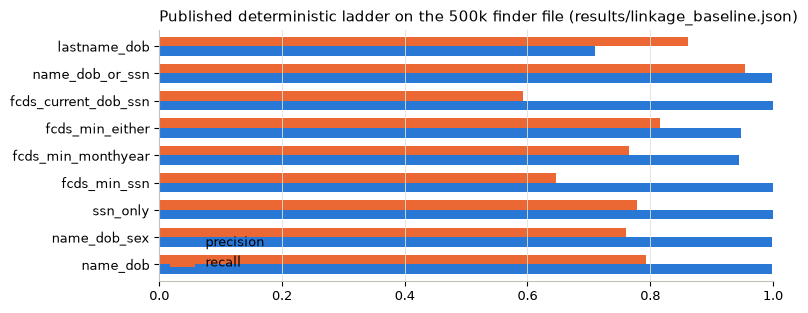

In [15]:
def score(rule_sql, t="finder_500k"):
    r = con.execute(f"""
        WITH reg AS (SELECT * FROM registry), fin AS (SELECT * FROM {t}),
        pred AS (SELECT DISTINCT reg.simulant_id AS r_id, fin.simulant_id AS f_id FROM reg JOIN fin ON {rule_sql})
        SELECT count(*) AS predicted, count(*) FILTER (WHERE r_id = f_id) AS tp,
               (SELECT count(DISTINCT simulant_id) FROM fin WHERE simulant_id IN (SELECT simulant_id FROM reg)) AS true_pairs
        FROM pred""").df().iloc[0]
    return r.tp / r.predicted, r.tp / r.true_pairs
rules = {
    "name + DOB": "reg.first_name = fin.first_name AND reg.last_name = fin.last_name AND reg.date_of_birth = fin.date_of_birth AND fin.first_name <> '' AND fin.last_name <> '' AND fin.date_of_birth <> ''",
    "SSN only": "reg.ssn = fin.ssn AND fin.ssn <> ''",
}
recomputed = {k: score(v) for k, v in rules.items()}
for k, (p, r) in recomputed.items():
    print(f"{k:12} precision {p:.4f}  recall {r:.4f}")
base = json.load(open(RESULTS / "linkage_baseline.json"))
ff = base["finder_files"]; entry = ff["finder_500k.csv"] if isinstance(ff, dict) else next(x for x in ff if "500k" in json.dumps(x))
brules = entry["rules"] if isinstance(entry, dict) and "rules" in entry else entry
brules = brules if isinstance(brules, list) else list(brules.values())
b = {(x.get("rule") or x.get("name")): x for x in brules}
check("recomputed name+DOB precision and recall equal the published baseline", abs(b["name_dob"]["precision"] - recomputed["name + DOB"][0]) < 1e-3 and abs(b["name_dob"]["recall"] - recomputed["name + DOB"][1]) < 1e-3, f"published P={b['name_dob']['precision']:.4f} R={b['name_dob']['recall']:.4f}")
check("name+DOB recall sits below the 88-93% real-data band (harder, not easier, than real files)", recomputed["name + DOB"][1] < 0.88, f"recall {recomputed['name + DOB'][1]:.3f}")
ladder = pd.DataFrame({k: {"precision": v["precision"], "recall": v["recall"]} for k, v in b.items()}).T
fig, ax = plt.subplots(figsize=(8, 3.2))
ladder.plot.barh(ax=ax, color=[BLUE, ORANGE], width=0.7); ax.set_xlim(0, 1); ax.grid(axis="x", color=GRID, lw=0.6); ax.legend(frameon=False, loc="lower left")
ax.set_title("Published deterministic ladder on the 500k finder file (results/linkage_baseline.json)", loc="left"); plt.tight_layout()

## 12. Provenance the receiver can read: seeds, versions, and what the build recorded

In [16]:
print("seeds:", CFG["seeds"])
print("noise:", CFG["noise"])
env = json.load(open(RESULTS / "environment.json"))
print({k: env[k] for k in ("dataset_version", "built_utc", "pseudopeople", "duckdb", "python", "build_wall_seconds", "peak_rss_mb")})
check("manifest and environment agree on the dataset version", MANIFEST["version"] == env["dataset_version"] == str(CFG["dataset"]["version"]), MANIFEST["version"])
check("manifest records the sampling design (pool, census years, finder year, age/sex target)", all(k in MANIFEST for k in ("registry_pool", "census_years", "finder_year", "age_sex_target")))

seeds: {'duckdb_sample': 42, 'psp_registry': 42, 'psp_finder': 1, 'postprocess': 999}
noise: {'registry': {'ssn_missing': 0.05, 'ssn_transposed': 0.0, 'address_missing': 0.01}, 'finder': {'ssn_missing': 0.2, 'ssn_transposed': 0.01, 'address_missing': 0.05}}
{'dataset_version': '0.3', 'built_utc': '2026-09-24T22:38:17+00:00', 'pseudopeople': '1.2.8', 'duckdb': '1.5.4', 'python': '3.11.15', 'build_wall_seconds': 678.1, 'peak_rss_mb': 23640.4}
PASS manifest and environment agree on the dataset version -- 0.3
PASS manifest records the sampling design (pool, census years, finder year, age/sex target)


## Summary

In [17]:
summary = pd.DataFrame(LOG, columns=["check", "result", "detail"])
n = summary.result.value_counts()
print(f"{n.get('PASS', 0)} PASS, {n.get('FAIL', 0)} FAIL, {n.get('NOTE', 0)} NOTE")
pd.set_option("display.max_colwidth", 120)
display(summary.style.apply(lambda s: ["color: #006300" if v == "PASS" else "color: #d03b3b" if v == "FAIL" else "color: #52514e" for v in s], subset=["result"]))
assert n.get("FAIL", 0) == 0, "some checks failed; see above"

37 PASS, 0 FAIL, 12 NOTE


,check,result,detail
0,registry.csv: MD5 and SHA-256 match the manifest,PASS,"MD5 0656cd4b..., 509.8 MB"
1,finder_500k.csv: MD5 and SHA-256 match the manifest,PASS,"MD5 6025e406..., 49.9 MB"
2,finder_100k.csv: MD5 and SHA-256 match the manifest,PASS,"MD5 ffbc3a53..., 10.0 MB"
3,zip bundle: MD5 and SHA-256 match the manifest,PASS,219 MB
4,registry.csv: columns are exactly the published layout,PASS,"simulant_id, first_name, middle_initial, last_name, date_of_birth, sex, race_ethnicity, street_number, street_name, unit_number, city, state, zipcode, ssn"
5,finder_500k.csv: columns are exactly the published layout,PASS,"simulant_id, first_name, middle_initial, last_name, date_of_birth, sex, race_ethnicity, street_number, street_name, unit_number, city, state, zipcode, ssn"
6,finder_100k.csv: columns are exactly the published layout,PASS,"simulant_id, first_name, middle_initial, last_name, date_of_birth, sex, race_ethnicity, street_number, street_name, unit_number, city, state, zipcode, ssn"
7,"registry.csv: 5,000,000 distinct people (target 5,000,000)",PASS,2 duplicated row(s) from duplication noise
8,"finder_500k.csv: 500,000 distinct people (target 500,000)",PASS,0 duplicated row(s) from duplication noise
9,"finder_100k.csv: 100,000 distinct people (target 100,000)",PASS,1 duplicated row(s) from duplication noise
